## 1. Install Dependencies & Login

In [1]:
!pip install -q bert-score tokenizers ijson
import os
from huggingface_hub import login
from kaggle_secrets import UserSecretsClient
user_secrets = UserSecretsClient()
HF_TOKEN = user_secrets.get_secret("HF")
os.environ["HF_TOKEN"] = HF_TOKEN
login(token=HF_TOKEN)
print("Logged in.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.1/61.1 kB 1.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 149.9/149.9 kB 3.6 MB/s eta 0:00:00


Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


Logged in.


## 2. Check GPU

In [2]:
import torch
print("CUDA:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("VRAM:", round(torch.cuda.get_device_properties(0).total_memory / 1e9, 1), "GB")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

CUDA: True
GPU: Tesla T4
VRAM: 15.6 GB
Device: cuda


## 3. Configuration — Prefix LM

**Architecture:** 12-layer Transformer with Prefix LM attention mask.
- Prefix tokens (first 75%) get **bidirectional** attention.
- Suffix tokens (last 25%) get **causal** attention.
- Loss computed only on suffix predictions.
- At inference: entire prompt is prefix (bidirectional), generation is causal with KV cache.

In [3]:
import os, random, json, time, math, zipfile, numpy as np
from tqdm.auto import tqdm
SEED = 42; random.seed(SEED); np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
HF_DATASET_REPO = "Exploration-Lab/CS-781-Capstone"
TRAIN_FILES = [
    "Phase_1_Pretraining/Train/train_supreme_court.json",
    "Phase_1_Pretraining/Train/train_high_courts.json",
    "Phase_1_Pretraining/Train/train_acts.json",
    "Phase_1_Pretraining/Train/train_tribunals.json",
]
SOURCE_WEIGHTS = {"train_supreme_court.json": 0.40, "train_high_courts.json": 0.30,
    "train_acts.json": 0.15, "train_tribunals.json": 0.15}
TEST_FILE = "Phase_1_Pretraining/Test/test.json"
# === Model: Prefix LM ===
VOCAB_SIZE = 32000; D_MODEL = 768; N_LAYERS = 12; N_HEADS = 12
HEAD_DIM = D_MODEL // N_HEADS; D_FF = 2048; MAX_SEQ_LEN = 1024
ROPE_BASE = 10000.0; DROPOUT = 0.1
PREFIX_RATIO = 0.75  # 75% of block is prefix (bidirectional), 25% is suffix (causal)
# === Training ===
TOTAL_TOKENS = 500_000_000; BLOCK_SIZE = 1024; BATCH_SIZE = 16
GRADIENT_ACCUMULATION_STEPS = 4; PEAK_LR = 5e-4; MIN_LR = 5e-6
WARMUP_STEPS = 2000; WEIGHT_DECAY = 0.1; BETA1 = 0.9; BETA2 = 0.95; GRAD_CLIP = 1.0
VAL_TOKENS = 5_000_000; VAL_INTERVAL_STEPS = 500; VAL_FRACTION = 0.03
TARGET_GENERATION_WORDS = 128; MAX_GENERATION_TOKENS = 384
TEMPERATURE = 0.5; TOP_P = 0.9; TOP_K = 50; REPETITION_PENALTY = 1.1
SAVE_INTERVAL_STEPS = 500; SAVE_TOTAL_LIMIT = 3
TOKENIZER_VOCAB_SIZE = 32000; TOKENIZER_MIN_FREQ = 2; TOKENIZER_SAMPLE_SIZE = 200_000
TOKENIZER_DIR = "/kaggle/working/legal_tokenizer_prefixlm"
OUTPUT_DIR = "/kaggle/working/cs781_prefixlm"
MODEL_OUTPUT_DIR = os.path.join(OUTPUT_DIR, "legal-prefixlm-final")
CHECKPOINT_DIR = os.path.join(OUTPUT_DIR, "checkpoints")
PREDICTION_PATH = os.path.join(OUTPUT_DIR, "prediction.json")
SUBMISSION_ZIP = os.path.join(OUTPUT_DIR, "submission.zip")
LOSS_PLOT_PATH = os.path.join(OUTPUT_DIR, "loss.png")
for d in [OUTPUT_DIR, MODEL_OUTPUT_DIR, CHECKPOINT_DIR, TOKENIZER_DIR]: os.makedirs(d, exist_ok=True)
print(f"Prefix LM: {N_LAYERS}L, d={D_MODEL}, prefix_ratio={PREFIX_RATIO}")

Prefix LM: 12L, d=768, prefix_ratio=0.75


In [4]:
import os
import numpy as np
from transformers import PreTrainedTokenizerFast
from huggingface_hub import hf_hub_download

# 1. Define Dataset Paths
DATASET_PATH = "/kaggle/input/datasets/wewake227788/m3-dataset-500m"
TOK_DIR = os.path.join(DATASET_PATH, "legal_tokenizer_prefixlm")
TRAIN_BIN = os.path.join(DATASET_PATH, "cs781_prefixlm", "train_tokens.bin")
VAL_BIN = os.path.join(DATASET_PATH, "cs781_prefixlm", "val_tokens.bin")

# 2. Load Tokenizer & Set Constants
print("Loading tokenizer from dataset...")
tokenizer = PreTrainedTokenizerFast.from_pretrained(TOK_DIR)
VOCAB_SIZE = len(tokenizer)
EOS_ID = tokenizer.eos_token_id
PAD_ID = tokenizer.pad_token_id
print(f"VOCAB_SIZE={VOCAB_SIZE}, EOS={EOS_ID}, PAD={PAD_ID}")

# 3. Load Memory-Mapped Token Binaries
# We use mode="r" because Kaggle dataset inputs are read-only
print("Loading memory-mapped arrays...")
train_mmap = np.memmap(TRAIN_BIN, dtype=np.uint32, mode="r")
val_mmap = np.memmap(VAL_BIN, dtype=np.uint32, mode="r")

# Strip any trailing zeros if the original quota wasn't 100% perfectly met
train_ptr = np.max(np.nonzero(train_mmap)) + 1
val_ptr = np.max(np.nonzero(val_mmap)) + 1

train_mmap = train_mmap[:train_ptr]
val_mmap = val_mmap[:val_ptr]

print(f"Train: {len(train_mmap):,} tokens")
print(f"Val: {len(val_mmap):,} tokens")

# 4. Download Test File 
# (Since we skipped Cell 4, we still need the test set for Section 18)
print("\nDownloading test file...")
test_file_path = hf_hub_download(
    repo_id=HF_DATASET_REPO, 
    filename=TEST_FILE, 
    repo_type="dataset", 
    token=HF_TOKEN
)
print(f"Test file ready: {test_file_path}")

Loading tokenizer from dataset...
VOCAB_SIZE=32000, EOS=1, PAD=0
Loading memory-mapped arrays...
Train: 500,000,000 tokens
Val: 5,000,000 tokens



test.json:   0%|          | 0.00/3.03M [00:00<?, ?B/s]

Test file ready: /root/.cache/huggingface/hub/datasets--Exploration-Lab--CS-781-Capstone/snapshots/89edba6a44d6bb9593fd13b6895b5cd3b06eb82e/Phase_1_Pretraining/Test/test.json


## 4. Download Data

In [5]:
# from huggingface_hub import hf_hub_download
# train_file_paths = {}
# for tf in TRAIN_FILES:
#     path = hf_hub_download(repo_id=HF_DATASET_REPO, filename=tf, repo_type="dataset", token=HF_TOKEN)
#     source_name = os.path.basename(tf)
#     train_file_paths[source_name] = path
#     print(f"Downloaded {source_name}: {path}")
# test_file_path = hf_hub_download(repo_id=HF_DATASET_REPO, filename=TEST_FILE, repo_type="dataset", token=HF_TOKEN)
# print(f"\nTest file: {test_file_path}")

## 5. Train BPE Tokenizer

In [6]:
# from tokenizers import Tokenizer, models, trainers, pre_tokenizers, decoders, processors
# from transformers import PreTrainedTokenizerFast
# import ijson, gc
# # --- Collect texts via streaming (reservoir sampling per source) ---
# print("Collecting texts for tokenizer training via weighted streaming...")
# tokenizer_quotas = {k: int(TOKENIZER_SAMPLE_SIZE * v) for k, v in SOURCE_WEIGHTS.items()}
# tokenizer_texts = []
# random.seed(SEED)
# for source_name, fpath in train_file_paths.items():
#     target = tokenizer_quotas.get(source_name, 0)
#     sampled = []
#     seen = 0
#     with open(fpath, "rb") as f:
#         for rec in tqdm(ijson.items(f, "item"), desc=f"Streaming {source_name}", unit=" docs"):
#             text = rec.get("text", "")
#             if not text.strip(): continue
#             if seen < target: sampled.append(text)
#             else:
#                 j = random.randint(0, seen)
#                 if j < target: sampled[j] = text
#             seen += 1
#     tokenizer_texts.extend(sampled)
#     print(f"  {source_name}: sampled {len(sampled)} from {seen}")
# print(f"Total tokenizer docs: {len(tokenizer_texts)}")
# # Write to temp file
# tok_file = os.path.join(TOKENIZER_DIR, "corpus.txt")
# with open(tok_file, "w", encoding="utf-8") as f:
#     for t in tqdm(tokenizer_texts, desc="Writing"):
#         c = t.replace("\n", " ").replace("\r", " ").strip()
#         if c: f.write(c + "\n")
# del tokenizer_texts; gc.collect()
# # Train BPE
# print(f"\nTraining BPE (vocab={TOKENIZER_VOCAB_SIZE})...")
# SPECIAL_TOKENS = ["<|pad|>", "<|eos|>", "<|bos|>", "<|unk|>"]
# tok = Tokenizer(models.BPE(unk_token="<|unk|>"))
# tok.pre_tokenizer = pre_tokenizers.ByteLevel(add_prefix_space=False)
# tok.decoder = decoders.ByteLevel()
# tok.post_processor = processors.ByteLevel(trim_offsets=True)
# trainer_obj = trainers.BpeTrainer(vocab_size=TOKENIZER_VOCAB_SIZE, min_frequency=TOKENIZER_MIN_FREQ,
#     special_tokens=SPECIAL_TOKENS, show_progress=True, initial_alphabet=pre_tokenizers.ByteLevel.alphabet())
# tok.train(files=[tok_file], trainer=trainer_obj)
# print(f"Vocab size: {tok.get_vocab_size()}")
# tok.save(os.path.join(TOKENIZER_DIR, "tokenizer.json"))
# tokenizer = PreTrainedTokenizerFast(tokenizer_object=tok, unk_token="<|unk|>",
#     eos_token="<|eos|>", bos_token="<|bos|>", pad_token="<|pad|>")
# tokenizer.save_pretrained(TOKENIZER_DIR)
# VOCAB_SIZE = len(tokenizer)
# EOS_ID = tokenizer.eos_token_id
# PAD_ID = tokenizer.pad_token_id
# print(f"VOCAB_SIZE={VOCAB_SIZE}, EOS={EOS_ID}, PAD={PAD_ID}")
# # Quick check
# for s in ["The appellant herein is the original plaintiff.", "Section 302 of the Indian Penal Code"]:
#     ids = tokenizer.encode(s, add_special_tokens=False)
#     assert tokenizer.decode(ids).strip() == s.strip()
# print("Tokenizer OK!")
# if os.path.exists(tok_file): os.remove(tok_file)

## 6. Tokenize & Save to Binary (Memory-Mapped)

In [7]:
# import ijson, gc
# TRAIN_BIN = os.path.join(OUTPUT_DIR, "train_tokens.bin")
# VAL_BIN = os.path.join(OUTPUT_DIR, "val_tokens.bin")
# random.seed(SEED)
# train_quotas = {k: int(TOTAL_TOKENS * v) for k, v in SOURCE_WEIGHTS.items()}
# val_quotas = {k: int(VAL_TOKENS * v) for k, v in SOURCE_WEIGHTS.items()}
# train_mmap = np.memmap(TRAIN_BIN, dtype=np.uint32, mode="w+", shape=(TOTAL_TOKENS,))
# val_mmap = np.memmap(VAL_BIN, dtype=np.uint32, mode="w+", shape=(VAL_TOKENS,))
# train_ptr = 0; val_ptr = 0
# print(f"Targeting {TOTAL_TOKENS:,} train + {VAL_TOKENS:,} val tokens")
# with tqdm(total=TOTAL_TOKENS+VAL_TOKENS, desc="Tokenizing", unit="tok", unit_scale=True) as pbar:
#     for src, fpath in train_file_paths.items():
#         t_quota = train_quotas[src]; v_quota = val_quotas[src]
#         t_done = 0; v_done = 0
#         with open(fpath, "rb") as f:
#             for rec in ijson.items(f, "item"):
#                 toks = tokenizer.encode(rec["text"], add_special_tokens=False) + [EOS_ID]  # EOS marks doc boundary
#                 if random.random() < VAL_FRACTION:
#                     if v_done < v_quota:
#                         n = min(len(toks), v_quota - v_done, VAL_TOKENS - val_ptr)
#                         if n > 0:
#                             val_mmap[val_ptr:val_ptr+n] = toks[:n]
#                             val_ptr += n; v_done += n; pbar.update(n)
#                 else:
#                     if t_done < t_quota:
#                         n = min(len(toks), t_quota - t_done, TOTAL_TOKENS - train_ptr)
#                         if n > 0:
#                             train_mmap[train_ptr:train_ptr+n] = toks[:n]
#                             train_ptr += n; t_done += n; pbar.update(n)
#                 if t_done >= t_quota and v_done >= v_quota: break
# train_mmap.flush(); val_mmap.flush(); del train_mmap, val_mmap
# print(f"Train: {train_ptr:,} tokens, Val: {val_ptr:,} tokens")
# print(f"Train file: {train_ptr*4/1e9:.2f} GB, Val file: {val_ptr*4/1e9:.2f} GB")
# # Re-open read-only (only the filled portion)
# train_mmap = np.memmap(TRAIN_BIN, dtype=np.uint32, mode="r")[:train_ptr]
# val_mmap = np.memmap(VAL_BIN, dtype=np.uint32, mode="r")[:val_ptr]
# gc.collect()

## 7. DataLoader & LR Scheduler

In [8]:
from torch.utils.data import IterableDataset, DataLoader, get_worker_info
class WSDScheduler:
    def __init__(self, peak_lr, min_lr, warmup_steps, total_steps, decay_frac=0.10):
        self.peak_lr = peak_lr; self.min_lr = min_lr; self.warmup_steps = warmup_steps
        self.total_steps = total_steps; self.decay_start = int(total_steps * (1 - decay_frac))
        self.decay_steps = total_steps - self.decay_start
    def get_lr(self, step):
        if step < self.warmup_steps: return self.peak_lr * step / max(self.warmup_steps, 1)
        if step < self.decay_start: return self.peak_lr
        p = (step - self.decay_start) / max(self.decay_steps, 1)
        return self.min_lr + (self.peak_lr - self.min_lr) * 0.5 * (1 + math.cos(math.pi * p))

class BlockDataset(IterableDataset):
    def __init__(self, mmap_tokens, block_size, batch_size, seed=42):
        self.mmap = mmap_tokens; self.block_size = block_size
        self.batch_size = batch_size; self.seed = seed; self.epoch = 0
        self.num_blocks = len(mmap_tokens) // block_size
        print(f"  BlockDataset: {self.num_blocks:,} blocks of {block_size}")
    def __iter__(self):
        info = get_worker_info()
        wid, nw = (info.id, info.num_workers) if info else (0, 1)
        # Same shuffle in every worker, then each worker takes a disjoint shard (no duplicated data)
        rng = random.Random(self.seed + self.epoch)
        indices = list(range(self.num_blocks)); rng.shuffle(indices)
        indices = indices[wid::nw]
        self.epoch += 1
        batch = []
        for idx in indices:
            s = idx * self.block_size
            batch.append(self.mmap[s:s+self.block_size].astype(np.int64))
            if len(batch) == self.batch_size:
                yield torch.tensor(np.array(batch), dtype=torch.long)
                batch = []

tokens_per_step = BATCH_SIZE * GRADIENT_ACCUMULATION_STEPS * BLOCK_SIZE
TOTAL_STEPS = TOTAL_TOKENS // tokens_per_step
lr_scheduler = WSDScheduler(PEAK_LR, MIN_LR, WARMUP_STEPS, TOTAL_STEPS)
print(f"Total steps: {TOTAL_STEPS:,}")
train_dataset = BlockDataset(train_mmap, BLOCK_SIZE, BATCH_SIZE, SEED)
train_loader = DataLoader(train_dataset, batch_size=None, num_workers=2, pin_memory=True, prefetch_factor=2)

Total steps: 7,629
  BlockDataset: 488,281 blocks of 1024


## 8. Model Components: RMSNorm + RoPE + SwiGLU

In [9]:
import torch.nn as nn
import torch.nn.functional as F
class RMSNorm(nn.Module):
    def __init__(self, dim, eps=1e-6):
        super().__init__()
        self.eps = eps
        self.weight = nn.Parameter(torch.ones(dim))
    def forward(self, x):
        rms = torch.rsqrt(x.float().pow(2).mean(-1, keepdim=True) + self.eps)
        return (x.float() * rms).type_as(x) * self.weight

def precompute_rope_freqs(dim, max_seq_len, base=10000.0):
    freqs = 1.0 / (base ** (torch.arange(0, dim, 2).float() / dim))
    t = torch.arange(max_seq_len, dtype=torch.float32)
    freqs = torch.outer(t, freqs)
    return torch.cos(freqs), torch.sin(freqs)

def apply_rope(x, freqs_cos, freqs_sin):
    x_r = x.reshape(*x.shape[:-1], -1, 2)
    x0, x1 = x_r[..., 0], x_r[..., 1]
    seq_len = x.shape[2]
    cos = freqs_cos[:seq_len].unsqueeze(0).unsqueeze(0).to(x.dtype)
    sin = freqs_sin[:seq_len].unsqueeze(0).unsqueeze(0).to(x.dtype)
    out0 = x0 * cos - x1 * sin
    out1 = x0 * sin + x1 * cos
    return torch.stack([out0, out1], dim=-1).reshape_as(x)

class SwiGLU_FFN(nn.Module):
    def __init__(self, d_model, d_ff, dropout=0.0):
        super().__init__()
        self.w_gate = nn.Linear(d_model, d_ff, bias=False)
        self.w_up = nn.Linear(d_model, d_ff, bias=False)
        self.w_down = nn.Linear(d_ff, d_model, bias=False)
        self.dropout = nn.Dropout(dropout)
    def forward(self, x):
        return self.dropout(self.w_down(F.silu(self.w_gate(x)) * self.w_up(x)))

## 9. Prefix LM Attention

A boolean attention mask gives **bidirectional** attention to prefix tokens and **causal** attention to suffix tokens, so the model can read the whole legal prompt before generating.

In [10]:
class PrefixLMAttention(nn.Module):
    """Self-attention with Prefix LM masking: bidirectional on prefix, causal on suffix."""
    def __init__(self, d_model, n_heads, head_dim, dropout=0.0):
        super().__init__()
        self.n_heads = n_heads; self.head_dim = head_dim
        self.q_proj = nn.Linear(d_model, n_heads * head_dim, bias=False)
        self.k_proj = nn.Linear(d_model, n_heads * head_dim, bias=False)
        self.v_proj = nn.Linear(d_model, n_heads * head_dim, bias=False)
        self.out_proj = nn.Linear(n_heads * head_dim, d_model, bias=False)
        self.attn_dropout = nn.Dropout(dropout)
        self.resid_dropout = nn.Dropout(dropout)
    def forward(self, x, freqs_cos, freqs_sin, prefix_len=None, use_cache=False, past_kv=None):
        B, T, _ = x.shape
        q = self.q_proj(x).view(B, T, self.n_heads, self.head_dim).transpose(1, 2)
        k = self.k_proj(x).view(B, T, self.n_heads, self.head_dim).transpose(1, 2)
        v = self.v_proj(x).view(B, T, self.n_heads, self.head_dim).transpose(1, 2)
        q = apply_rope(q, freqs_cos, freqs_sin)
        k = apply_rope(k, freqs_cos, freqs_sin)
        if past_kv is not None:
            k = torch.cat([past_kv[0], k], dim=2)
            v = torch.cat([past_kv[1], v], dim=2)
        new_kv = (k, v) if use_cache else None
        dp = self.attn_dropout.p if self.training else 0.0
        if past_kv is not None:
            # Cached decoding: new token(s) attend to everything before them -> no mask needed
            out = F.scaled_dot_product_attention(q, k, v, dropout_p=dp)
        elif prefix_len is None:
            out = F.scaled_dot_product_attention(q, k, v, is_causal=True, dropout_p=dp)
        elif prefix_len >= T:
            # Entire sequence is prefix -> fully bidirectional (used for the prompt at inference)
            out = F.scaled_dot_product_attention(q, k, v, dropout_p=dp)
        else:
            # Boolean Prefix-LM mask (True = may attend): causal, plus every row sees all prefix columns
            mask = torch.tril(torch.ones(T, T, device=x.device, dtype=torch.bool))
            mask[:, :prefix_len] = True
            out = F.scaled_dot_product_attention(q, k, v, attn_mask=mask, dropout_p=dp)
        out = out.transpose(1, 2).contiguous().view(B, T, -1)
        return self.resid_dropout(self.out_proj(out)), new_kv

## 10. Transformer Block

In [11]:
class TransformerBlock(nn.Module):
    def __init__(self, d_model, n_heads, head_dim, d_ff, dropout=0.0):
        super().__init__()
        self.attn_norm = RMSNorm(d_model)
        self.attn = PrefixLMAttention(d_model, n_heads, head_dim, dropout)
        self.ffn_norm = RMSNorm(d_model)
        self.ffn = SwiGLU_FFN(d_model, d_ff, dropout)
    def forward(self, x, freqs_cos, freqs_sin, prefix_len=None, use_cache=False, past_kv=None):
        attn_out, new_kv = self.attn(self.attn_norm(x), freqs_cos, freqs_sin, prefix_len, use_cache, past_kv)
        x = x + attn_out
        x = x + self.ffn(self.ffn_norm(x))
        return x, new_kv

## 11. Full Model: PrefixLegalLM (~85M non-embedding params)

In [12]:
from torch.utils.checkpoint import checkpoint as grad_checkpoint
class PrefixLegalLM(nn.Module):
    def __init__(self, vocab_size, d_model, n_layers, n_heads, head_dim, d_ff,
                 max_seq_len, rope_base=10000.0, dropout=0.0, use_gc=True):
        super().__init__()
        self.d_model = d_model; self.n_layers = n_layers; self.vocab_size = vocab_size
        self.max_seq_len = max_seq_len; self.use_gc = use_gc
        self.tok_emb = nn.Embedding(vocab_size, d_model)
        self.emb_dropout = nn.Dropout(dropout)
        self.layers = nn.ModuleList([TransformerBlock(d_model, n_heads, head_dim, d_ff, dropout) for _ in range(n_layers)])
        self.final_norm = RMSNorm(d_model)
        self.lm_head = nn.Linear(d_model, vocab_size, bias=False)
        self.lm_head.weight = self.tok_emb.weight  # Tied embeddings
        fc, fs = precompute_rope_freqs(head_dim, max_seq_len, rope_base)
        self.register_buffer("freqs_cos", fc, persistent=False)
        self.register_buffer("freqs_sin", fs, persistent=False)
        self._init_weights()
    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Linear):
                torch.nn.init.normal_(m.weight, std=0.02)
                if m.bias is not None: torch.nn.init.zeros_(m.bias)
            elif isinstance(m, nn.Embedding):
                torch.nn.init.normal_(m.weight, std=0.02)
        for layer in self.layers:
            s = 0.02 / math.sqrt(2 * self.n_layers)
            torch.nn.init.normal_(layer.attn.out_proj.weight, std=s)
            torch.nn.init.normal_(layer.ffn.w_down.weight, std=s)
    def forward(self, input_ids, targets=None, prefix_len=None, use_cache=False, past_kvs=None):
        B, T = input_ids.shape
        x = self.emb_dropout(self.tok_emb(input_ids))
        past_len = past_kvs[0][0].shape[2] if past_kvs is not None else 0
        fc = self.freqs_cos[past_len:past_len+T]
        fs = self.freqs_sin[past_len:past_len+T]
        presents = [] if use_cache else None
        for i, layer in enumerate(self.layers):
            pkv = past_kvs[i] if past_kvs is not None else None
            if self.use_gc and self.training:
                x, _ = grad_checkpoint(layer, x, fc, fs, prefix_len, False, None, use_reentrant=False)
            else:
                x, kv = layer(x, fc, fs, prefix_len, use_cache, pkv)
                if use_cache: presents.append(kv)
        x = self.final_norm(x)
        logits = self.lm_head(x)
        loss = None
        if targets is not None:
            shift_logits = logits[:, :-1, :].contiguous()
            shift_targets = targets[:, 1:].clone()
            # Loss only on suffix tokens: target index j predicts token j+1, so mask j < prefix_len-1
            if prefix_len is not None and prefix_len > 0:
                shift_targets[:, :prefix_len-1] = -100
            loss = F.cross_entropy(shift_logits.view(-1, self.vocab_size), shift_targets.view(-1), ignore_index=-100)
        return logits, loss, presents
    @torch.no_grad()
    def generate(self, input_ids, max_new_tokens, temperature=0.7, top_p=0.9,
                 top_k=50, repetition_penalty=1.1, eos_token_id=None):
        """Prefix-LM generation: prompt is encoded bidirectionally (prefix_len=T), then decoded causally with KV cache."""
        self.eval(); B, T = input_ids.shape
        generated = input_ids; past_kvs = None
        for _ in range(max_new_tokens):
            if past_kvs is not None:
                curr = generated[:, -1:]; plen = None
            else:
                curr = generated; plen = T
            logits, _, past_kvs = self.forward(curr, prefix_len=plen, use_cache=True, past_kvs=past_kvs)
            logits = logits[:, -1, :].float()
            if repetition_penalty != 1.0:
                for b in range(B):
                    idx = torch.unique(generated[b])
                    sel = logits[b, idx]
                    logits[b, idx] = torch.where(sel > 0, sel / repetition_penalty, sel * repetition_penalty)
            logits = logits / temperature
            if top_k > 0:
                topk_v, _ = torch.topk(logits, min(top_k, logits.size(-1)))
                logits[logits < topk_v[:, -1:]] = float('-inf')
            if top_p < 1.0:
                sl, si = torch.sort(logits, descending=True)
                cp = torch.cumsum(F.softmax(sl, dim=-1), dim=-1)
                rm = cp > top_p; rm[:, 1:] = rm[:, :-1].clone(); rm[:, 0] = False
                for b in range(B): logits[b, si[b][rm[b]]] = float('-inf')
            probs = F.softmax(logits, dim=-1)
            next_tok = torch.multinomial(probs, num_samples=1)
            generated = torch.cat([generated, next_tok], dim=1)
            if eos_token_id is not None and (next_tok == eos_token_id).all(): break
        return generated

model = PrefixLegalLM(VOCAB_SIZE, D_MODEL, N_LAYERS, N_HEADS, HEAD_DIM, D_FF,
    MAX_SEQ_LEN, ROPE_BASE, DROPOUT, use_gc=True).to(device)
model = torch.compile(model)
total_params = sum(p.numel() for p in model.parameters())
unique_params = total_params - model.tok_emb.weight.numel()
print(f"PrefixLM params (excl. tied embeddings): {unique_params:,} ({unique_params/1e6:.1f}M)")
assert 50_000_000 <= unique_params <= 300_000_000

PrefixLM params (excl. tied embeddings): 84,953,856 (85.0M)


## 12. Optimizer & Mixed Precision

In [13]:
decay_p = []; no_decay_p = []
for name, p in model.named_parameters():
    if not p.requires_grad: continue
    if "norm" in name or "bias" in name or "tok_emb" in name: no_decay_p.append(p)
    else: decay_p.append(p)
optimizer = torch.optim.AdamW([{"params": decay_p, "weight_decay": WEIGHT_DECAY},
    {"params": no_decay_p, "weight_decay": 0.0}], lr=PEAK_LR, betas=(BETA1, BETA2), fused=True)
scaler = torch.amp.GradScaler("cuda")
print(f"Optimizer: {len(decay_p)} decay + {len(no_decay_p)} no-decay params")

Optimizer: 84 decay + 26 no-decay params


## 13. Validation Function

In [14]:
@torch.no_grad()
def evaluate_val(model, val_mmap, block_size, prefix_len, device, max_batches=50):
    model.eval(); total_loss = 0.0; n = 0
    num_blocks = len(val_mmap) // block_size
    for i in range(0, min(num_blocks, max_batches * 8), 8):
        batch_blocks = []
        for j in range(i, min(i + 8, num_blocks)):
            batch_blocks.append(val_mmap[j*block_size:(j+1)*block_size].astype(np.int64))
        ids = torch.tensor(np.array(batch_blocks), dtype=torch.long, device=device)
        with torch.amp.autocast("cuda", dtype=torch.float16):
            _, loss, _ = model(ids, targets=ids, prefix_len=prefix_len)
        total_loss += loss.item(); n += 1
        if n >= max_batches: break
    avg = total_loss / max(n, 1); ppl = math.exp(min(avg, 20))
    model.train(); return avg, ppl

## 14. Checkpoint Functions

In [15]:
def save_checkpoint(model, optimizer, scaler, step, loss, path):
    torch.save({"model_state_dict": model.state_dict(), "optimizer_state_dict": optimizer.state_dict(),
        "scaler_state_dict": scaler.state_dict(), "step": step, "loss": loss}, path)
    print(f"  Checkpoint saved: step {step}, loss {loss:.4f}")

def load_checkpoint(path, model, optimizer=None, scaler=None):
    ckpt = torch.load(path, map_location=device, weights_only=False)
    model.load_state_dict(ckpt["model_state_dict"])
    if optimizer and "optimizer_state_dict" in ckpt: optimizer.load_state_dict(ckpt["optimizer_state_dict"])
    if scaler and "scaler_state_dict" in ckpt: scaler.load_state_dict(ckpt["scaler_state_dict"])
    return ckpt["step"], ckpt.get("loss")

def cleanup_checkpoints(ckpt_dir, keep=3):
    ckpts = sorted([f for f in os.listdir(ckpt_dir) if f.startswith("step_") and f.endswith(".pt")],
        key=lambda x: int(x.split("_")[1].split(".")[0]))
    while len(ckpts) > keep: os.remove(os.path.join(ckpt_dir, ckpts.pop(0)))

## 15. Training Loop

In [16]:
import os
import time
from tqdm.auto import tqdm

# 1. Provide the exact path to your checkpoint file here.
# 1. Provide the exact path to your checkpoint file here.
RESUME_CHECKPOINT_PATH = "/kaggle/input/datasets/demonhunter24/m3-ckpts/cs781_prefixlm/checkpoints/step_7000.pt"

# 2. Setup Resume Variables
start_step = 0
tokens_seen = 0

if RESUME_CHECKPOINT_PATH and os.path.exists(RESUME_CHECKPOINT_PATH):
    print(f"Resuming training from explicit checkpoint: {RESUME_CHECKPOINT_PATH}")
    start_step, _ = load_checkpoint(RESUME_CHECKPOINT_PATH, model, optimizer, scaler)
    # Calculate tokens already seen so logs stay accurate
    tokens_seen = start_step * BATCH_SIZE * GRADIENT_ACCUMULATION_STEPS * BLOCK_SIZE
else:
    print("No checkpoint loaded. Starting from scratch.")

# 3. Standard Setup
PREFIX_LEN = int(BLOCK_SIZE * PREFIX_RATIO)
print(f"Prefix LM training: prefix_len={PREFIX_LEN}, suffix_len={BLOCK_SIZE-PREFIX_LEN}")
model.train(); train_log = []; val_log = []
best_val_loss = float("inf"); best_step = start_step
start_time = time.time(); running_loss = 0.0
train_iter = iter(train_loader)

# 4. Training Loop (Starting from start_step)
for step in tqdm(range(start_step, TOTAL_STEPS), desc="Training", initial=start_step, total=TOTAL_STEPS):
    lr = lr_scheduler.get_lr(step)
    for pg in optimizer.param_groups: pg["lr"] = lr
    optimizer.zero_grad(set_to_none=True)
    accum_loss = 0.0
    
    for _ in range(GRADIENT_ACCUMULATION_STEPS):
        try: batch = next(train_iter)
        except StopIteration: train_iter = iter(train_loader); batch = next(train_iter)
        batch = batch.to(device, non_blocking=True)
        
        with torch.amp.autocast("cuda", dtype=torch.float16):
            _, loss, _ = model(batch, targets=batch, prefix_len=PREFIX_LEN)
            loss_s = loss / GRADIENT_ACCUMULATION_STEPS
            
        scaler.scale(loss_s).backward()
        accum_loss += loss.item()
        
    scaler.unscale_(optimizer)
    torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
    scaler.step(optimizer); scaler.update()
    
    avg_loss = accum_loss / GRADIENT_ACCUMULATION_STEPS
    running_loss += avg_loss
    tokens_seen += BATCH_SIZE * GRADIENT_ACCUMULATION_STEPS * BLOCK_SIZE
    
    if (step+1) % 100 == 0:
        rl = running_loss / 100
        train_log.append({"step": step+1, "loss": rl, "lr": lr})
        tqdm.write(f"Step {step+1}/{TOTAL_STEPS} | Loss: {rl:.4f} | LR: {lr:.2e} | Tok: {tokens_seen/1e6:.0f}M")
        running_loss = 0.0
        
    if (step+1) % VAL_INTERVAL_STEPS == 0:
        vl, vp = evaluate_val(model, val_mmap, BLOCK_SIZE, PREFIX_LEN, device)
        val_log.append({"step": step+1, "val_loss": vl, "val_ppl": vp})
        tqdm.write(f"  VAL: loss={vl:.4f} ppl={vp:.2f}")
        if vl < best_val_loss:
            best_val_loss = vl; best_step = step + 1
            save_checkpoint(model, optimizer, scaler, step+1, vl, os.path.join(CHECKPOINT_DIR, "best.pt"))
            
    if (step+1) % SAVE_INTERVAL_STEPS == 0:
        save_checkpoint(model, optimizer, scaler, step+1, avg_loss, os.path.join(CHECKPOINT_DIR, f"step_{step+1}.pt"))
        cleanup_checkpoints(CHECKPOINT_DIR, SAVE_TOTAL_LIMIT)

total_time = time.time() - start_time
print(f"\nDone! {total_time/3600:.2f}h, best val loss: {best_val_loss:.4f}")

Resuming training from explicit checkpoint: /kaggle/input/datasets/demonhunter24/m3-ckpts/cs781_prefixlm/checkpoints/step_7000.pt
Prefix LM training: prefix_len=768, suffix_len=256


Training:  92%|#########1| 7000/7629 [00:00<?, ?it/s]

W1004 11:26:23.340000 22 torch/_inductor/utils.py:1731] [0/0] Not enough SMs to use max_autotune_gemm mode


Step 7100/7629 | Loss: 2.3948 | LR: 3.95e-04 | Tok: 465M
Step 7200/7629 | Loss: 2.3839 | LR: 3.02e-04 | Tok: 472M
Step 7300/7629 | Loss: 2.3443 | LR: 2.00e-04 | Tok: 478M
Step 7400/7629 | Loss: 2.2986 | LR: 1.08e-04 | Tok: 485M
Step 7500/7629 | Loss: 2.3021 | LR: 3.96e-05 | Tok: 492M
  VAL: loss=2.7787 ppl=16.10
  Checkpoint saved: step 7500, loss 2.7787
  Checkpoint saved: step 7500, loss 2.3051
Step 7600/7629 | Loss: 2.2769 | LR: 6.89e-06 | Tok: 498M

Done! 0.95h, best val loss: 2.7787


## 16. Plot Loss

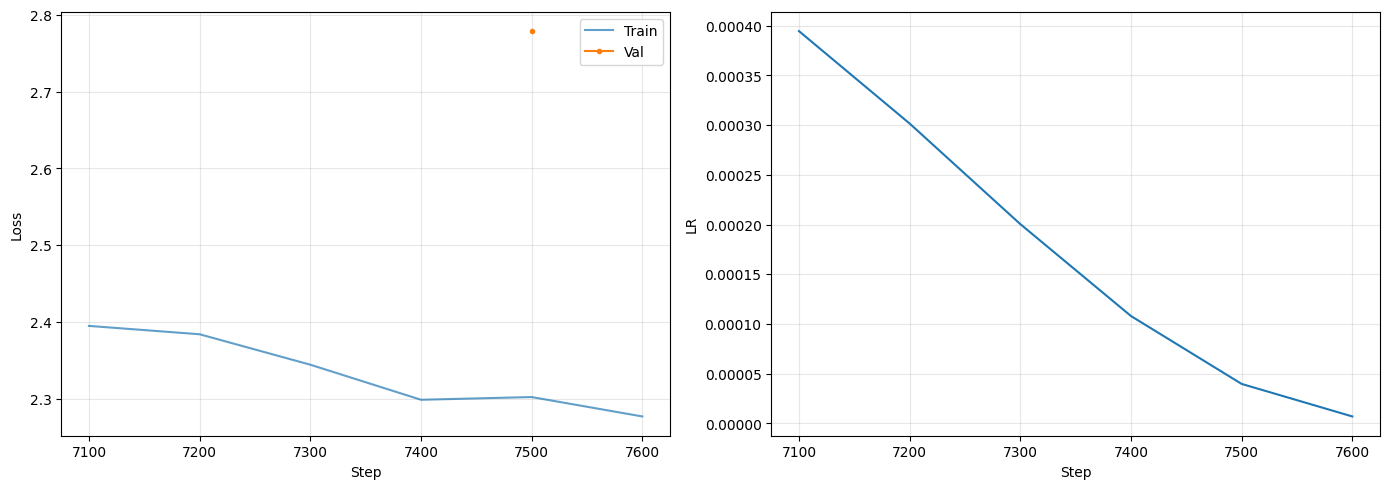

In [17]:
import matplotlib.pyplot as plt
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
ax1.plot([d["step"] for d in train_log], [d["loss"] for d in train_log], label="Train", alpha=0.7)
ax1.plot([d["step"] for d in val_log], [d["val_loss"] for d in val_log], label="Val", marker="o", ms=3)
ax1.set_xlabel("Step"); ax1.set_ylabel("Loss"); ax1.legend(); ax1.grid(True, alpha=0.3)
ax2.plot([d["step"] for d in train_log], [d["lr"] for d in train_log])
ax2.set_xlabel("Step"); ax2.set_ylabel("LR"); ax2.grid(True, alpha=0.3)
plt.tight_layout(); plt.savefig(LOSS_PLOT_PATH, dpi=150); plt.show()

## 17. Load Best Checkpoint

In [18]:
print("Loading best checkpoint...")
load_checkpoint(os.path.join(CHECKPOINT_DIR, "best.pt"), model)
print("Best model loaded.")

Loading best checkpoint...
Best model loaded.


## 18. Load Test Prompts

In [19]:
with open(test_file_path, "r", encoding="utf-8") as f:
    test_data = json.load(f)
print(f"Test examples: {len(test_data)}")

Test examples: 1000


## 19. Generation Function

In [20]:
def generate_continuations(prompts, model, tokenizer, device,
                           target_words=128, max_new_tokens=384,
                           temperature=0.5, top_p=0.9, top_k=50,
                           repetition_penalty=1.1, max_input_tokens=None):
    if max_input_tokens is None: max_input_tokens = MAX_SEQ_LEN - max_new_tokens
    model.eval(); results = []
    for prompt in tqdm(prompts, desc="Generating", leave=False):
        ids = tokenizer.encode(prompt, add_special_tokens=False)
        if len(ids) > max_input_tokens: ids = ids[-max_input_tokens:]
        inp = torch.tensor([ids], dtype=torch.long, device=device)
        inp_len = inp.shape[1]
        with torch.no_grad():
            out = model.generate(inp, max_new_tokens=max_new_tokens, temperature=temperature,
                top_p=top_p, top_k=top_k, repetition_penalty=repetition_penalty,
                eos_token_id=tokenizer.eos_token_id)
        gen_text = tokenizer.decode(out[0, inp_len:].tolist(), skip_special_tokens=True)
        results.append(" ".join(gen_text.split()[:target_words]))
    return results

## 20. Generate Predictions

In [21]:
model.eval(); predictions = {}
items = list(test_data.items())
gen_start = time.time()
with torch.inference_mode(), torch.amp.autocast("cuda", dtype=torch.float16):
    for idx, (eid, rec) in enumerate(tqdm(items, desc="Generating predictions")):
        cont = generate_continuations([rec["text"]], model, tokenizer, device,
            target_words=TARGET_GENERATION_WORDS, max_new_tokens=MAX_GENERATION_TOKENS,
            temperature=TEMPERATURE, top_p=TOP_P, top_k=TOP_K, repetition_penalty=REPETITION_PENALTY)[0]
        predictions[str(eid)] = {"text": cont}
gen_time = time.time() - gen_start
print(f"Generation: {gen_time:.0f}s ({gen_time/len(items):.2f}s/example)")

Generating predictions:   0%|          | 0/1000 [00:00<?, ?it/s]

Generating:   0%|          | 0/1 [00:00<?, ?it/s]

Generating:   0%|          | 0/1 [00:00<?, ?it/s]

Generating:   0%|          | 0/1 [00:00<?, ?it/s]

Generating:   0%|          | 0/1 [00:00<?, ?it/s]

Generating:   0%|          | 0/1 [00:00<?, ?it/s]

... (992 outputs left out)

Generating:   0%|          | 0/1 [00:00<?, ?it/s]

Generating:   0%|          | 0/1 [00:00<?, ?it/s]

Generating:   0%|          | 0/1 [00:00<?, ?it/s]

Generation: 5678s (5.68s/example)


## 21. Save Model

In [22]:
torch.save({"model_state_dict": model.state_dict(),
    "config": {"arch": "prefix_lm", "vocab_size": VOCAB_SIZE, "d_model": D_MODEL,
        "n_layers": N_LAYERS, "n_heads": N_HEADS, "d_ff": D_FF, "prefix_ratio": PREFIX_RATIO}
}, os.path.join(MODEL_OUTPUT_DIR, "model.pt"))
tokenizer.save_pretrained(MODEL_OUTPUT_DIR)
print(f"Model saved to {MODEL_OUTPUT_DIR}")

Model saved to /kaggle/working/cs781_prefixlm/legal-prefixlm-final


## 22. Save Predictions & Create ZIP

In [23]:
with open(PREDICTION_PATH, "w", encoding="utf-8") as f:
    json.dump(predictions, f, ensure_ascii=False, indent=2)
assert set(str(k) for k in test_data.keys()) == set(predictions.keys()), "ID mismatch!"
print(f"Saved {len(predictions)} predictions")

with zipfile.ZipFile(SUBMISSION_ZIP, "w", compression=zipfile.ZIP_DEFLATED) as zipf:
    zipf.write(PREDICTION_PATH, arcname="prediction.json")
print(f"ZIP: {SUBMISSION_ZIP} ({os.path.getsize(SUBMISSION_ZIP)/1024:.1f} KB)")

Saved 1000 predictions
ZIP: /kaggle/working/cs781_prefixlm/submission.zip (142.1 KB)


## 23. Sample Quality Check

In [24]:
print("=" * 80)
for eid, rec in list(test_data.items())[:3]:
    pred = predictions[str(eid)]["text"]
    print(f"\nID: {eid}")
    print(f"PROMPT (last 80 words): ...{' '.join(rec['text'].split()[-80:])}")
    print(f"GENERATED ({len(pred.split())} words): {pred[:300]}...")
    print("-" * 80)


ID: 1
PROMPT (last 80 words): ...has been reiterated in [State of Rajasthan & Ors. Vs. D.R. Laxmi & Ors.], (1996) 6 SCC 445, wherein this Court has held that even the void proceedings need not be set at naught if the party has not approached the Court within reasonable time, as judicial review is not permissible at a belated stage. This Court held as under: " Delay in challenging the notification was fatal and writ petition entails with dismissal on grounds of laches. It is
GENERATED (128 words): well settled that in a case where the High Court has quashed the notification, the court must give reasons for the delay in approaching the Court. The court must consider the facts and circumstances of each case and decide the question as to whether the acquisition is legal or not. In a given case, ...
--------------------------------------------------------------------------------

ID: 2
PROMPT (last 80 words): ...Present case was produced before me because Smt. Saroj Nand Das, Judicial Magi

## 24. Training Summary

In [25]:
print("=" * 60)
print("PREFIX LM TRAINING SUMMARY")
print("=" * 60)
print(f"Architecture: Prefix LM (bidirectional prefix + causal suffix)")
print(f"Parameters (excl. tied embeddings): {unique_params/1e6:.1f}M")
print(f"Layers: {N_LAYERS}, Heads: {N_HEADS}, d_model: {D_MODEL}")
print(f"Prefix ratio: {PREFIX_RATIO} ({int(BLOCK_SIZE*PREFIX_RATIO)} prefix, {BLOCK_SIZE-int(BLOCK_SIZE*PREFIX_RATIO)} suffix)")
print(f"Components: RoPE + RMSNorm + SwiGLU + Tied Embeddings")
print(f"Best val loss: {best_val_loss:.4f} (step {best_step})")
print(f"Training time: {total_time/3600:.2f}h")
print("=" * 60)

PREFIX LM TRAINING SUMMARY
Architecture: Prefix LM (bidirectional prefix + causal suffix)
Parameters (excl. tied embeddings): 85.0M
Layers: 12, Heads: 12, d_model: 768
Prefix ratio: 0.75 (768 prefix, 256 suffix)
Components: RoPE + RMSNorm + SwiGLU + Tied Embeddings
Best val loss: 2.7787 (step 7500)
Training time: 0.95h
